# Project: Car Price prediction

##  Project overview

The goal of this project is to develop a machine learning model that predicts used car prices based on vehicle characteristics.

The project follows the main steps of a machine learning workflow:

- Exploratory Data Analysis (EDA)

- Data Cleaning

- Feature Engineering

- Data Preprocessing

- Model Training

- Model Evaluation and Comparison

The regression models will be evaluated using MAE, MSE, RMSE, and R².


## 1. Intro

Before training a regression model, we need to understand the data.

A raw dataset can contain many problems:

- inconsistent column names,
- missing values,
- numbers stored as text,
- categorical values written inconsistently,
- invalid dates or times,
- invalid coordinates,
- target values stored in the wrong format.

If we train a model before checking these issues, the model may fail, or it may learn from unreliable data.

In this notebook, the goal is to inspect the dataset and identify what needs to be cleaned later.

## 2. Import libraries

We start by importing the libraries needed for basic data exploration.

- Pathlib is used to define and manage file paths.

- Pandas is used to load, inspect, and analyze the dataset.


- NumPy provides numerical operations.

- Matplotlib and Seaborn are used for data visualization.



In [21]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Define the data path

The path below assumes the following project structure:

In [22]:
DATA_PATH = "../data/cars.csv"

## 4. Load the dataset

First, load the CSV file and inspect a few rows. This helps us confirm that the file was read correctly and understand the structure of the dataset.

In [23]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 56244
Columns: 12


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


## 5. Understand the columns and data types

The target variable is 'priceUSD'. All other columns describe the car and may be used as input features. Numeric columns can be summarized statistically, while categorical columns contain labels such as make, fuel type, and transmission.

In [24]:
display(df.info())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 56244 entries, 0 to 56243
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make                 56244 non-null  str    
 1   model                56244 non-null  str    
 2   priceUSD             56244 non-null  int64  
 3   year                 56244 non-null  int64  
 4   condition            56244 non-null  str    
 5   mileage(kilometers)  56244 non-null  float64
 6   fuel_type            56244 non-null  str    
 7   volume(cm3)          56197 non-null  float64
 8   color                56244 non-null  str    
 9   transmission         56244 non-null  str    
 10  drive_unit           54339 non-null  str    
 11  segment              50953 non-null  str    
dtypes: float64(2), int64(2), str(8)
memory usage: 5.1 MB


None

,priceUSD,year,mileage(kilometers),volume(cm3)
count,56244.000000,56244.000000,5.624400e+04,56197.000000
mean,7415.456440,2003.454840,2.443956e+05,2104.860615
std,8316.959261,8.144247,3.210307e+05,959.201633
min,48.000000,1910.000000,0.000000e+00,500.000000
25%,2350.000000,1998.000000,1.370000e+05,1600.000000
50%,5350.000000,2004.000000,2.285000e+05,1996.000000
75%,9807.500000,2010.000000,3.100000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000


## 6. Inspect the Target Variable

Price is the value that the model will predict. We review its descriptive statistics and unique values to understand its scale and check whether there are missing or unexpected target values.

In [25]:
target_column = "priceUSD"

print("Target data type:", df[target_column].dtype)
print("Missing target values:", df[target_column].isna().sum())
print("Non-positive target values:", (df[target_column] <= 0).sum())
display(df[target_column].describe().to_frame(name=target_column))

Target data type: int64
Missing target values: 0
Non-positive target values: 0


,priceUSD
count,56244.000000
mean,7415.456440
std,8316.959261
min,48.000000
25%,2350.000000
50%,5350.000000
75%,9807.500000
max,235235.000000


## 7. Missing Values

First, we count missing values in each column. We will decide how to handle them later, during cleaning and preprocessing.

In [26]:
missing_values = df.isna().sum().sort_values(ascending=False)
missing_values = missing_values[missing_values > 0]
display(missing_values.to_frame(name="Missing values"))

,Missing values
segment,5291
drive_unit,1905
volume(cm3),47


### Visualization: Missing Values by Column


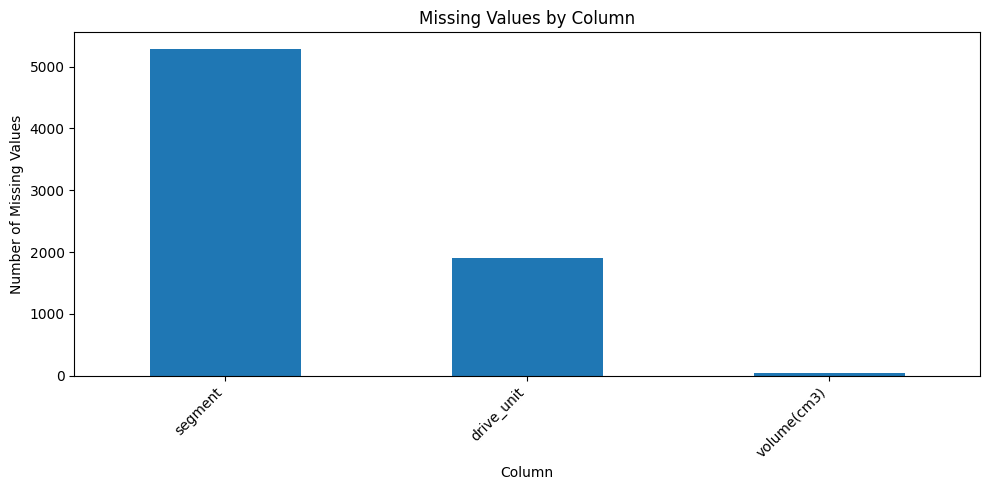

In [27]:
if missing_values.empty:
    print("No missing values were detected.")
else:
    plt.figure(figsize=(10, 5))
    missing_values.plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 8. Duplicate rows

Duplicate records may affect data analysis and model training. We count complete duplicate rows here but do not remove them in the EDA notebook.

In [28]:
duplicate_count = int(df.duplicated().sum())
print(f"Complete duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    display(df.loc[df.duplicated(keep=False)].head(10))

Complete duplicate rows: 87


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
1637,audi,100,1100,1989,with mileage,350000.0,petrol,2300.0,burgundy,mechanics,front-wheel drive,E
1695,audi,100,1280,1991,with mileage,305000.0,petrol,2300.0,red,mechanics,front-wheel drive,E
1930,audi,100,1280,1991,with mileage,305000.0,petrol,2300.0,red,mechanics,front-wheel drive,E
2011,audi,100,2000,1988,with mileage,350000.0,petrol,2300.0,blue,mechanics,front-wheel drive,E
2054,audi,100,2000,1988,with mileage,350000.0,petrol,2300.0,blue,mechanics,front-wheel drive,E
2140,audi,100,1100,1989,with mileage,350000.0,petrol,2300.0,burgundy,mechanics,front-wheel drive,E
2178,peugeot,106,700,2000,with mileage,27000.0,diesel,1500.0,blue,mechanics,front-wheel drive,B
2179,peugeot,106,700,2000,with mileage,27000.0,diesel,1500.0,blue,mechanics,front-wheel drive,B
4048,peugeot,406,1300,1995,with mileage,390000.0,petrol,1800.0,green,mechanics,front-wheel drive,D
4113,peugeot,406,2200,1995,with mileage,330000.0,petrol,1800.0,gray,mechanics,front-wheel drive,D


## 9. Numeric Column Inspection

The numeric columns are "priceUSD", "year", "mileage(kilometers)", and "volume(cm3). We inspect thair types, summary statistics, and    possible extreme values."

In [29]:
numeric_columns = [
    "priceUSD",
    "year",
    "mileage(kilometers)",
    "volume(cm3)"
]

print(df[numeric_columns].dtypes)
print(df[numeric_columns].describe())

priceUSD                 int64
year                     int64
mileage(kilometers)    float64
volume(cm3)            float64
dtype: object
            priceUSD          year  mileage(kilometers)   volume(cm3)
count   56244.000000  56244.000000         5.624400e+04  56197.000000
mean     7415.456440   2003.454840         2.443956e+05   2104.860615
std      8316.959261      8.144247         3.210307e+05    959.201633
min        48.000000   1910.000000         0.000000e+00    500.000000
25%      2350.000000   1998.000000         1.370000e+05   1600.000000
50%      5350.000000   2004.000000         2.285000e+05   1996.000000
75%      9807.500000   2010.000000         3.100000e+05   2300.000000
max    235235.000000   2019.000000         9.999999e+06  20000.000000


## 10. Categorical Column Inspection

Categorical column describe labels rather then measurements. We inspect their number of unique values and the most common categories.

In [30]:
categorical_columns = [
     "make", "model", "condition", "fuel_type",
    "color", "transmission", "drive_unit", "segment",
]

category_summary = pd.DataFrame({
    "Unique values": df[categorical_columns].nunique(dropna=False),
    "Missing_values": df[categorical_columns].isna().sum()
})

display(category_summary.sort_values("Unique values", ascending=False))

,Unique values,Missing_values
model,1034,0
make,96,0
color,13,0
segment,10,5291
drive_unit,5,1905
condition,3,0
fuel_type,3,0
transmission,2,0


In [31]:
for column in ["condition", "transmission", "drive_unit", "segment", "color"]:
    print(f"\n{column}")
    display(df[column].value_counts(dropna=False).head(15).to_frame(name="Count"))


condition


,Count
condition,
with mileage,55278
with damage,512
for parts,454



transmission


,Count
transmission,
mechanics,36056
auto,20188



drive_unit


,Count
drive_unit,
front-wheel drive,38016
rear drive,6836
all-wheel drive,5890
part-time four-wheel drive,3597
NaN,1905



segment


,Count
segment,
D,12605
C,10617
J,8629
M,6313
E,6274
NaN,5291
B,4393
F,896
S,765



color


,Count
color,
black,12385
silver,10075
blue,8083
gray,5807
white,5292
green,3911
other,3397
red,2744
burgundy,2026


## 11. Visualize the Target: Distribution of Car Prices

This histogram shows the distribution of "priceUSD". A smal number of expensive cars can make the distribution highly skewed. We show     both  the full range and a zoomed view limited to the 99th percentile.    
The origanal data remains unchanged.

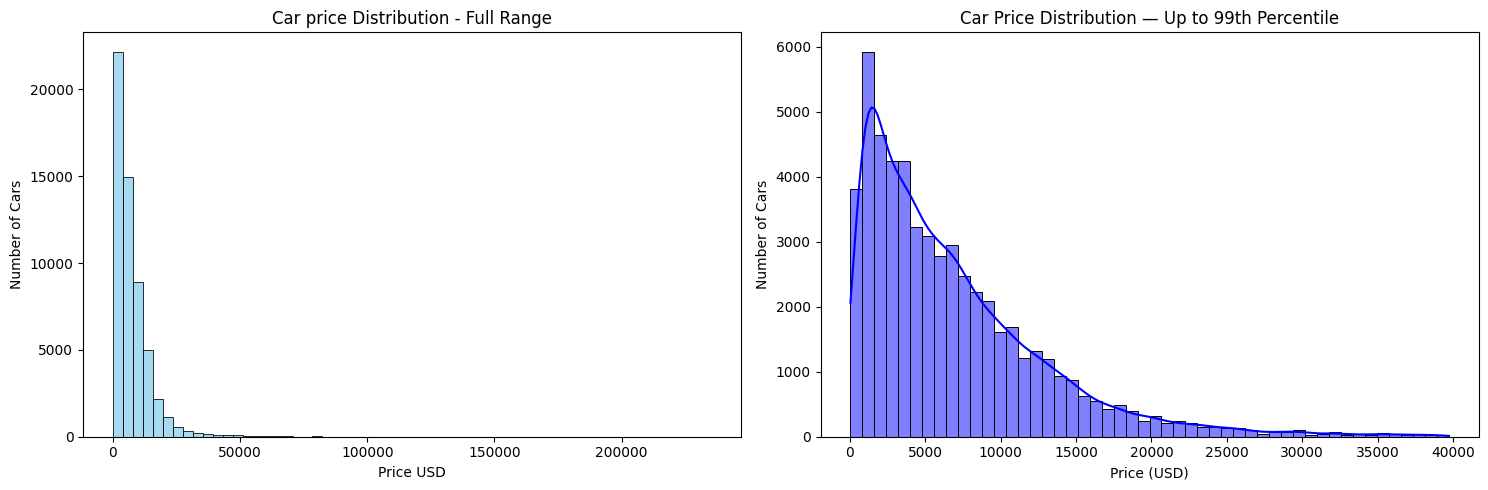

In [32]:
price_99 = df[target_column].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df[target_column].dropna(), bins=60, color= "skyblue", ax = axes[0])
axes[0].set_title("Car price Distribution - Full Range")
axes[0].set_xlabel("Price USD")
axes[0].set_ylabel("Number of Cars")

sns.histplot(df.loc[df[target_column] <= price_99, target_column].dropna(), bins = 50, kde = True, color="blue", ax=axes[1])
axes[1].set_title("Car Price Distribution — Up to 99th Percentile")
axes[1].set_xlabel("Price (USD)")
axes[1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

### Boxplot: Car Prices

A boxplot helps highlight prices far from the central range. These points are potential outliers and need    
context befor any cleaning decision is made.

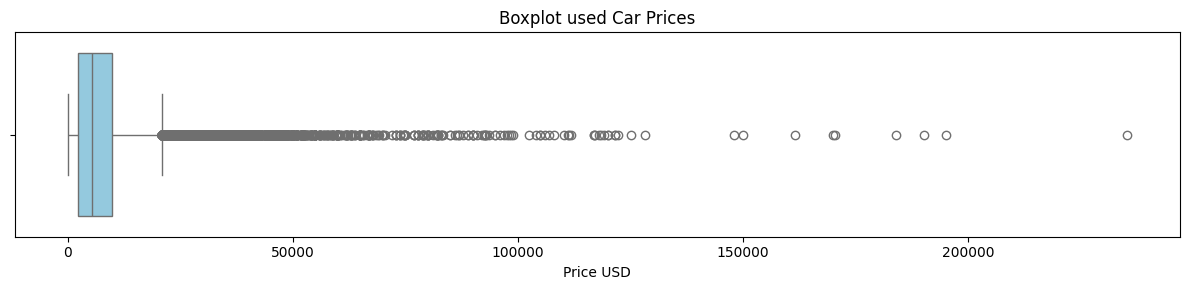

In [33]:
plt.figure(figsize=(12, 3))
sns.boxplot(x=df[target_column], color="skyblue")
plt.title("Boxplot used Car Prices")
plt.xlabel("Price USD")
plt.tight_layout()
plt.show()

## 12. Visualize Year and Mileage

We examine the distribution of production years and mileage. The second plot is limited to the 99th percentile for readability; it does not modify the original data.

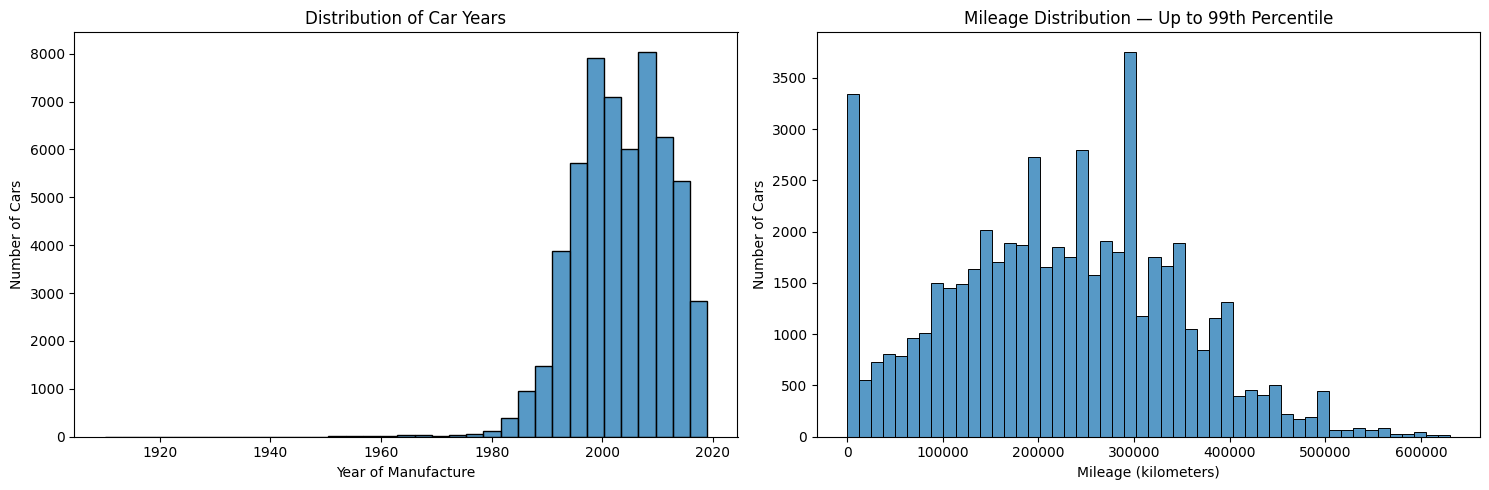

In [34]:
mileage_column = "mileage(kilometers)"
mileage_99 = df[mileage_column].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df["year"].dropna(), bins=35, color="C0", ax=axes[0])
axes[0].set_title("Distribution of Car Years")
axes[0].set_xlabel("Year of Manufacture")
axes[0].set_ylabel("Number of Cars")

sns.histplot(df.loc[df[mileage_column] <= mileage_99, mileage_column].dropna(), bins=50, color="C0", ax=axes[1])
axes[1].set_title("Mileage Distribution — Up to 99th Percentile")
axes[1].set_xlabel("Mileage (kilometers)")
axes[1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

## 13. Explore Relationships with Price

The scater plots show how price is related to year of manufacture and mileage. We use a random sample to keep the plots readable. Ths Plots show associations, not causation.

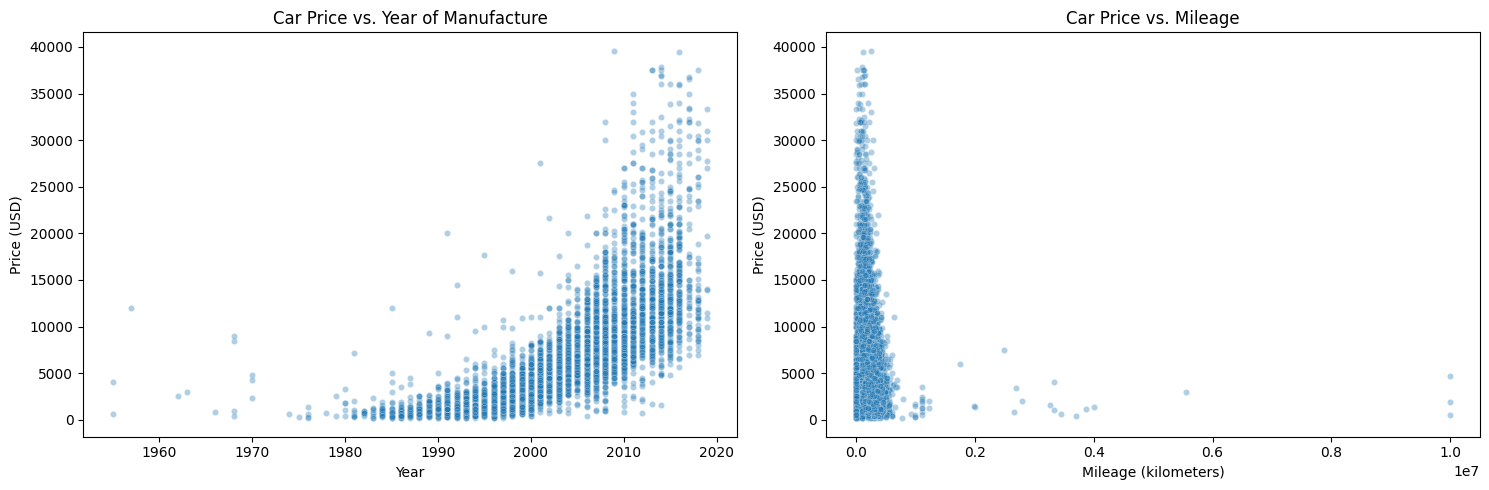

In [35]:
plot_columns = ["year", mileage_column, target_column]
plot_df = df.loc[df[target_column] <= price_99, plot_columns].dropna()
plot_df = plot_df.sample(n=min(5000, len(plot_df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=plot_df, x="year", y=target_column, alpha=0.35, s=20, color="C0", ax=axes[0])
axes[0].set_title("Car Price vs. Year of Manufacture")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Price (USD)")

sns.scatterplot(data=plot_df, x=mileage_column, y=target_column, alpha=0.35, s=20, color="C0", ax=axes[1])
axes[1].set_title("Car Price vs. Mileage")
axes[1].set_xlabel("Mileage (kilometers)")
axes[1].set_ylabel("Price (USD)")

plt.tight_layout()
plt.show()

## 14. Compare Median Price by Fuel Type

The bar compares median price across fuel type. Median is used because it is less affected by unusually high prices than the mean.

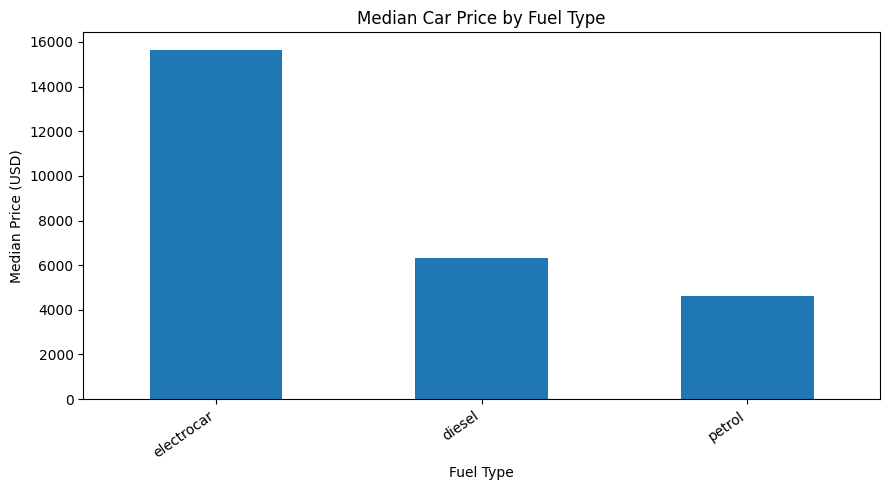

In [36]:
median_price_by_fuel = df.groupby("fuel_type", dropna=False)[target_column].median().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
median_price_by_fuel.plot(kind="bar")
plt.title("Median Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Median Price (USD)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 15. Correlation Between Numaric Variables

A correlation heatmap shows linear relationships between numerical variables. Correlation does not prove causation, and it may not capture non-linear relationships.

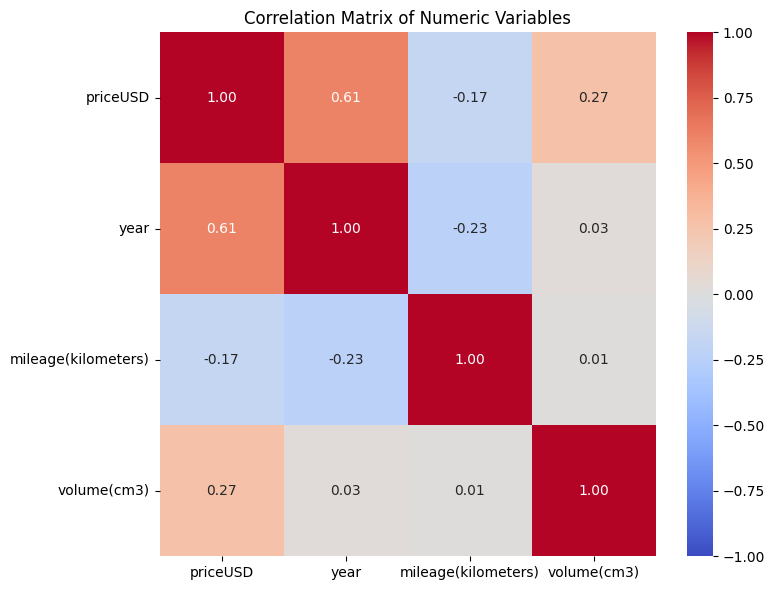

In [37]:
correlation_columns = ["priceUSD", "year", mileage_column, "volume(cm3)"]
correlation_matrix = df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0, fmt=".2f")
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()

## 16. Final EDA Findings and Cleaning Plan

The following code summarizes key data-quality checks. Review the printed results before writing data-cleaning rules. Potential outliers will be investigated rather than automatically deleted.

In [38]:
print("EDA SUMMARY")
print("-" * 50)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate rows: {int(df.duplicated().sum()):,}")
print(f"Missing target values: {int(df[target_column].isna().sum()):,}")
print(f"Non-positive prices: {int((df[target_column] <= 0).sum()):,}")
print(f"Minimum year: {df['year'].min():.0f}")
print(f"Maximum year: {df['year'].max():.0f}")
print(f"Minimum price: ${df[target_column].min():,.0f}")
print(f"Median price: ${df[target_column].median():,.0f}")
print(f"Maximum price: ${df[target_column].max():,.0f}")
print("\nColumns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False).to_string())

EDA SUMMARY
--------------------------------------------------
Rows: 56,244
Columns: 12
Duplicate rows: 87
Missing target values: 0
Non-positive prices: 0
Minimum year: 1910
Maximum year: 2019
Minimum price: $48
Median price: $5,350
Maximum price: $235,235

Columns with missing values:
segment        5291
drive_unit     1905
volume(cm3)      47


### Cleaning Plan

Based on the EDA checks, the next phase should:

1. Standardize column names so they are easier to use in Python.
2. Remove complete duplicate rows.
3. Keep only rows with a valid, positive target price.
4. Convert numeric fields to numeric types and treat impossible feature values as missing.
5. Standardize categorical text values.
6. Handle remaining missing numeric and categorical values in the preprocessing pipeline.
7. Investigate extreme prices, years, and mileage carefully instead of removing them only because they are unusual.

The cleaning and feature-engineering operations will be implemented in separate Python scripts, as required by the project brief.

## 17. Conclusion

EDA is not the modeling stage. It helps us understand the dataset and prepare a clear plan for cleaning. The next notebook demonstrates the modeling workflow, while reusable operations are implemented in the `src` folder.